# Dataset EDA & Data-Quality Report

**Project:** Kidzonia — AI-Assisted Scoliosis Screening System
**Dataset:** `public_datasets/scoliosis/` — YOLOv8-pose, 12-point spine keypoint schema
**Purpose:** verify the public scoliosis dataset is fit for the fine-tuned YOLO + anatomy-aware
geometry pipeline (`src/FeatureExtraction/spine_geometry.py`) *before* spending more time
extending that model.

This notebook runs the same checks as `src/Evaluation/dataset_eda.py` step by step, with
charts and inline sample images at each stage. It reuses that script's functions directly
(no logic is duplicated) and writes the same output files to `Data/Processed/eda/`, so running
this notebook top-to-bottom reproduces everything the CLI script produces, with visuals added.

**Keypoint schema** (`src/config/keypoint_schema.py`):

| kp | name | kp | name |
|---|---|---|---|
| 0 | spine_base_lumbar | 6 | spine_intermediate_6 |
| 1 | spine_intermediate_1 | 7 | spine_intermediate_7 |
| 2 | spine_intermediate_2 | 8 | spine_top_cervical |
| 3 | spine_intermediate_3 | 9 | left_shoulder |
| 4 | spine_intermediate_4 | 10 | right_shoulder |
| 5 | spine_intermediate_5 | 11 | neck_head_center |

---
## Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

PROJECT_ROOT = Path().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Reuse the tested EDA logic directly — this notebook does not reimplement it.
from src.Evaluation.dataset_eda import (
    DATASET_DIR, DATA_YAML, OUTPUT_DIR, SPLITS, KP_GROUPS,
    load_class_names, process_split, check_leakage,
    build_class_distribution_table, build_keypoint_visibility_table, build_geometry_readiness,
    geometry_reliability_verdict, save_sample_overlays,
    imdecode_unicode, cv2,
)

SPLIT_COLORS = {'train': '#4C72B0', 'valid': '#DD8452', 'test': '#55A868', 'ALL': '#8172B2'}
CLASS_COLORS = {'normal': '#55A868', 'scoliosis': '#C44E52'}

print(f'Project root : {PROJECT_ROOT}')
print(f'Dataset dir  : {DATASET_DIR}')
print(f'cv2 available: {cv2 is not None}')

Project root : C:\Users\jiang\OneDrive\桌面\Scoliosis Screening Project
Dataset dir  : C:\Users\jiang\OneDrive\桌面\Scoliosis Screening Project\public_datasets\scoliosis
cv2 available: True


## Step 1 — Load class schema

Reads `nc` / `names` from `scoliosis_train.yaml` so every label's class id can be checked for
validity, not just counted blindly.

In [2]:
class_names, nc = load_class_names(DATA_YAML)
valid_class_ids = set(class_names.keys()) if class_names else None

print(f'Classes (nc={nc}): {class_names}')
if not class_names:
    print('[WARN] Could not load class names — class-id validity check will be disabled.')

Classes (nc=2): {0: 'normal', 1: 'scoliosis'}


## Step 2 — Parse & validate every split

For each of `train` / `valid` / `test`, this pairs up images with label files and checks, per
object: token count, numeric parsing, class-id validity, bbox/keypoint coordinate range, and
keypoint visibility-flag validity. It also runs every ground-truth object through
`extract_spine_geometry()` (with keypoint confidence simulated from the label's visibility flag)
to see whether the *labels themselves* would support the anatomy-aware geometry features.

In [3]:
split_results = {split: process_split(split, valid_class_ids) for split in SPLITS}

for split, res in split_results.items():
    s = res['summary']
    print(f"{split:6s}: {s['num_images']:3d} images, {s['num_objects']:3d} objects, "
          f"{len(res['issue_rows']):2d} flagged issue(s)")

train : 135 images, 138 objects,  7 flagged issue(s)
valid :  37 images,  36 objects,  1 flagged issue(s)
test  :  19 images,  19 objects,  0 flagged issue(s)


## Step 3 — Build summary tables

Same aggregation the CLI script writes to CSV: split-level summary, class distribution,
per-keypoint visibility, and geometry-readiness — assembled here as DataFrames for display
and plotting.

In [4]:
summary_df = pd.DataFrame([res['summary'] for res in split_results.values()])
class_df   = build_class_distribution_table(split_results, class_names)
kp_vis_df  = build_keypoint_visibility_table(split_results)
geom_df    = build_geometry_readiness(split_results, kp_vis_df)

issue_rows = [row for res in split_results.values() for row in res['issue_rows']]
issues_df  = pd.DataFrame(issue_rows) if issue_rows else pd.DataFrame(columns=['split', 'stem', 'n_objects', 'issues'])

display(summary_df)

,split,num_images,num_label_files,missing_label_files,missing_image_files,unreadable_images,empty_label_files,malformed_label_files,num_objects,avg_objects_per_image,max_objects_per_image,images_with_multi_objects,class_imbalance_ratio,avg_visible_kp_per_object,geometry_valid_pct,geometry_checked_count,geometry_valid_count
0,train,135,135,0,0,0,4,0,138,1.053,7,2,1.34,12.0,99.3,138,137
1,valid,37,37,0,0,0,1,0,36,1.000,1,0,1.12,12.0,100.0,36,36
2,test,19,19,0,0,0,0,0,19,1.000,1,0,2.80,12.0,100.0,19,19


## Visual 1 — Split overview

**What it shows:** image count, labeled-object count, and class-imbalance ratio for each split.

- **Images vs. objects per split** — these should be close; a gap just means some images contain
  more than one annotated subject. A big gap is worth a manual look — either a packaging issue or
  genuinely multi-subject images.
- **Class-imbalance ratio** = majority class count ÷ minority class count for that split.
  - **Good:** close to 1.0 — both classes are roughly equally represented.
  - **Concerning:** ratio ≳ 2.0 — the minority class has few examples, so any metric computed on
    it (e.g. scoliosis recall) becomes noisy and should be read as indicative only.
  - There's no fixed pass/fail cutoff here — a small **test** split will naturally show a higher
    ratio just from the luck of the draw; what matters most is whether **train** is imbalanced
    enough to bias what the model actually learns.


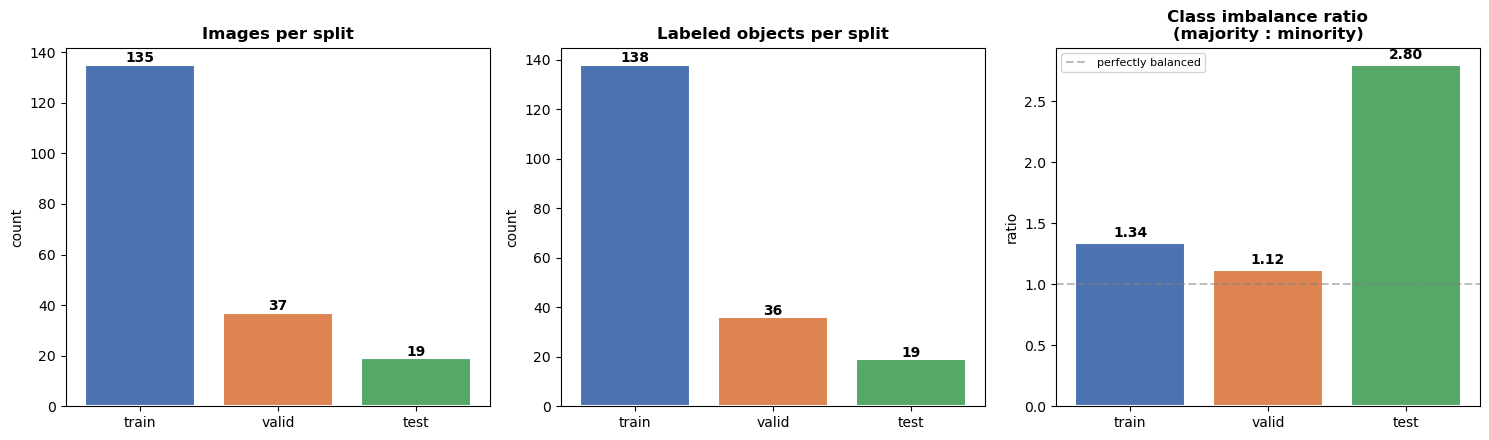

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

labels = summary_df['split'].tolist()
colors = [SPLIT_COLORS[l] for l in labels]

axes[0].bar(labels, summary_df['num_images'], color=colors, edgecolor='white', linewidth=1.5)
axes[0].set_title('Images per split', fontweight='bold')
axes[0].set_ylabel('count')
for i, v in enumerate(summary_df['num_images']):
    axes[0].text(i, v + 1, str(v), ha='center', fontweight='bold')

axes[1].bar(labels, summary_df['num_objects'], color=colors, edgecolor='white', linewidth=1.5)
axes[1].set_title('Labeled objects per split', fontweight='bold')
axes[1].set_ylabel('count')
for i, v in enumerate(summary_df['num_objects']):
    axes[1].text(i, v + 1, str(v), ha='center', fontweight='bold')

axes[2].bar(labels, summary_df['class_imbalance_ratio'], color=colors, edgecolor='white', linewidth=1.5)
axes[2].axhline(1.0, color='grey', linestyle='--', alpha=0.5, label='perfectly balanced')
axes[2].set_title('Class imbalance ratio\n(majority : minority)', fontweight='bold')
axes[2].set_ylabel('ratio')
axes[2].legend(fontsize=8)
for i, v in enumerate(summary_df['class_imbalance_ratio']):
    axes[2].text(i, v + 0.05, f'{v:.2f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_split_overview.png', dpi=150, bbox_inches='tight')
plt.show()

## Visual 2 — Class distribution & imbalance

**What it shows:** the same imbalance ratio from Visual 1, broken out into actual normal vs.
scoliosis counts per split, so you can see *which* class is short and by how much.

- **Good:** the two bars in a split are close in height.
- **Problematic:** one class is a small slice of the split — most importantly in **test**, since
  that's what accuracy/recall numbers are computed on. A test split with only a handful of
  positive cases (as here) means a single misclassified image swings the recall figure a lot —
  treat it as a rough signal, not a precise metric.


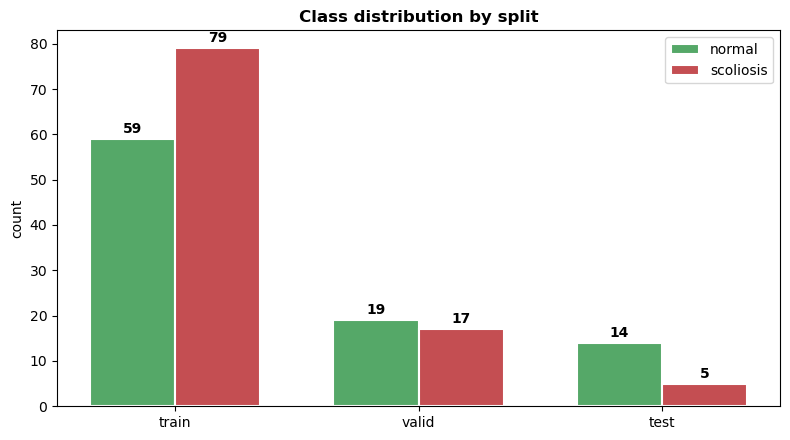

,split,class_id,class_name,count,pct_of_split
0,train,0,normal,59,42.8
1,train,1,scoliosis,79,57.2
2,valid,0,normal,19,52.8
3,valid,1,scoliosis,17,47.2
4,test,0,normal,14,73.7
5,test,1,scoliosis,5,26.3
6,ALL,0,normal,92,47.7
7,ALL,1,scoliosis,101,52.3


In [6]:
pivot = class_df[class_df['split'] != 'ALL'].pivot(index='split', columns='class_name', values='count').reindex(SPLITS)

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(pivot.index))
width = 0.35
for i, cls in enumerate(pivot.columns):
    bars = ax.bar(x + (i - 0.5) * width, pivot[cls], width, label=cls,
                   color=CLASS_COLORS.get(cls, None), edgecolor='white', linewidth=1.5)
    ax.bar_label(bars, padding=2, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(pivot.index)
ax.set_ylabel('count')
ax.set_title('Class distribution by split', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

display(class_df)

## Visual 3 — Label quality issues

**What it shows:** every image/label pair that failed at least one integrity check, and which
check(s) it failed. An empty table here is the "good" outcome — it means every downstream check
(visibility, geometry readiness) is being computed on trustworthy data.

**What each issue tag means, and why it matters:**

| Issue tag | Meaning | Why it matters |
|---|---|---|
| `missing_label_file` | An image has no matching `.txt` label | Unusable for training/eval — no ground truth at all |
| `missing_image_file` | A label file has no matching image | Orphaned annotation, wasted/dead label |
| `empty_label_file` | Label file exists but has zero objects | Usually an intentional "negative" background image — **not automatically a bug**, but worth confirming with the dataset source |
| `malformed_lines=N` | N label lines didn't parse (wrong token count / non-numeric) | The object is unusable — a training run would skip or error on it |
| `invalid_class_id=X` | Class id isn't in `nc`/`names` from the data yaml | Object would be mislabeled or rejected during training |
| `bbox_coord_out_of_range` | A bounding-box value is outside `[0, 1]` | Normalized coords should stay within-frame; usually a minor edge-of-frame overshoot |
| `kp_coord_out_of_range_xN` | N keypoints are outside `[0, 1]` | Same idea, for keypoints — the point was (or was placed) partially off-frame |
| `invalid_visibility_xN` | N keypoints have a visibility flag other than `{0, 1, 2}` | Violates the YOLO-pose visibility convention — likely an annotation-export bug |
| `unreadable_image` | Image file exists but OpenCV can't decode it | Corrupt file or wrong extension |

**Rough severity, high → low:** `missing_label_file` / `missing_image_file` / `malformed_lines` /
`invalid_class_id` (object is unusable) → `invalid_visibility` (breaks visibility-based checks
everywhere downstream) → `kp_coord_out_of_range` / `bbox_coord_out_of_range` (usually a harmless
edge-of-frame overshoot in practice) → `empty_label_file` (often intentional, lowest concern).


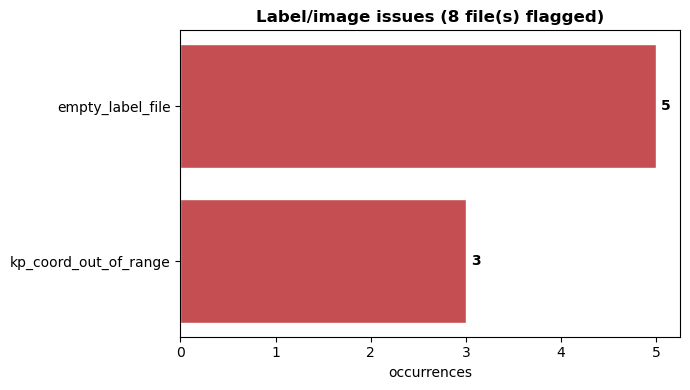

,split,stem,n_objects,issues
0,train,273_png_jpg.rf.2a0ccb64e63a4ac1f0f14c9416b33d7e,0,empty_label_file
1,train,505_jpeg_jpg.rf.d52b7168e5c81a5c73fe6882a45d7578,0,empty_label_file
2,train,534_jpg.rf.b3fd26da34cd65924820dfc4f2ab1411,0,empty_label_file
3,train,6_png_jpg.rf.3ac6e11cc773fb41b18eb86ab248a52b,0,empty_label_file
4,train,8_png_jpg.rf.8b553373ac66d9547fb69b2a75db9ad8,1,kp_coord_out_of_range_x1
5,train,Person-1_png.rf.4cea93d1d62f7210ebe9b7ff0c826a45,1,kp_coord_out_of_range_x1
6,train,Person-5_png.rf.8aa218652fc8decd32ded0ceb7bd17bf,1,kp_coord_out_of_range_x1
7,valid,4_png_jpg.rf.41ef9e8cadbd001dfb867200b839110e,0,empty_label_file


In [7]:
if issues_df.empty:
    print('No label/image issues found in any split.')
else:
    issue_types = issues_df['issues'].str.split('; ').explode().str.replace(r'_x\d+$', '', regex=True)
    counts = issue_types.value_counts()

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.barh(counts.index[::-1], counts.values[::-1], color='#C44E52', edgecolor='white')
    ax.set_xlabel('occurrences')
    ax.set_title(f'Label/image issues ({len(issues_df)} file(s) flagged)', fontweight='bold')
    for i, v in enumerate(counts.values[::-1]):
        ax.text(v + 0.05, i, str(v), va='center', fontweight='bold')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'fig_label_issues.png', dpi=150, bbox_inches='tight')
    plt.show()

    display(issues_df)

## Step 4 — Train / valid / test leakage check

Checks whether the *same* image (by filename, or by exact file content via MD5) appears in
more than one split — a common cause of inflated validation/test metrics.

- **Good:** 0 duplicate filenames and 0 duplicate content hashes. Train/valid/test are genuinely
  independent, so a good validation/test score reflects generalisation rather than the model
  having partly memorised images that also sit in the split you're scoring it on.
- **Problematic:** any count > 0. A duplicate **filename** across splits is worth a look (could be
  coincidental naming, e.g. two unrelated photos both called `image1.jpg`), but a duplicate
  **content hash** is unambiguous — it's the literal same image bytes in two splits, i.e. real
  leakage — and any split containing it should be treated as compromised until it's fixed.


In [8]:
dupe_names, dupe_hashes = check_leakage(split_results)

print(f'Duplicate filenames across splits : {len(dupe_names)}')
print(f'Duplicate image content (md5)     : {len(dupe_hashes)}')

if dupe_hashes:
    print('\nContent-identical images found across splits:')
    for h, splits in dupe_hashes.items():
        print(f'  {h[:12]}...  -> {splits}')
else:
    print('\nNo cross-split leakage detected.')

Duplicate filenames across splits : 0
Duplicate image content (md5)     : 0

No cross-split leakage detected.


## Visual 4 — Keypoint visibility by index

**What it shows:** for each of the 12 keypoints, the % of labeled objects where that point is
marked visible (`v == 2`) in the ground truth — as a bar chart (grouped by anatomical role) and
a split × keypoint heatmap.

- **Good:** visibility rate close to 100% — green cells in the heatmap.
- **Concerning:** a keypoint sitting well below the rest of its group, or a whole split noticeably
  redder than the others — that specific point (or split) can't be trusted for the features that
  depend on it.
- **Which points feed which feature (why this matters downstream):**
  - kp[0] / kp[8] (spine base/top) → `spine_axis_inclination_deg` — if either is missing, **no**
    geometry feature can be computed at all, since everything else is measured relative to this line.
  - kp[1..7] (intermediate spine) → `max/mean_lateral_deviation_px`, `curve_smoothness_score` —
    the points that describe the actual curve shape, not just its two endpoints.
  - kp[9] / kp[10] (shoulders) → `shoulder_height_difference_px`, `shoulder_line_angle_deg`.
  - There's no single hard cutoff for "bad" at this stage — visibility here is a sliding scale
    that directly determines the verdict in Visual 5.


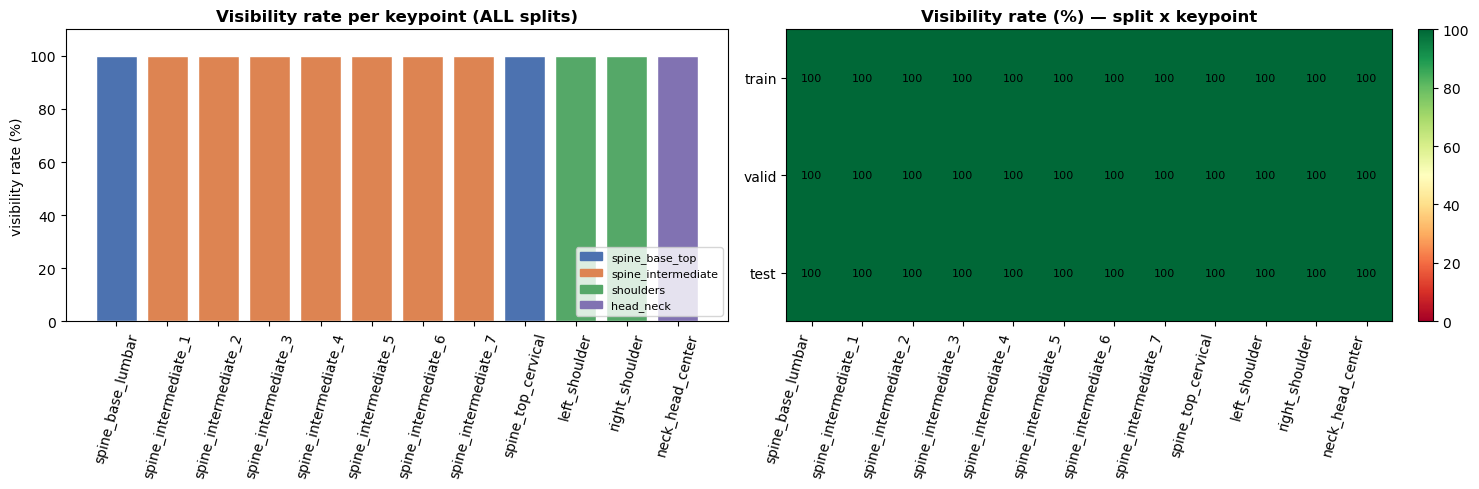

In [9]:
all_kp = kp_vis_df[kp_vis_df['split'] == 'ALL'].sort_values('kp_index')
group_colors = {
    'spine_base_top':     '#4C72B0',
    'spine_intermediate': '#DD8452',
    'shoulders':          '#55A868',
    'head_neck':          '#8172B2',
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

bar_colors = [group_colors[g] for g in all_kp['group']]
axes[0].bar(all_kp['kp_name'], all_kp['visibility_rate_pct'], color=bar_colors, edgecolor='white')
axes[0].set_ylim(0, 110)
axes[0].set_ylabel('visibility rate (%)')
axes[0].set_title('Visibility rate per keypoint (ALL splits)', fontweight='bold')
axes[0].tick_params(axis='x', rotation=75)
handles = [mpatches.Patch(color=c, label=g) for g, c in group_colors.items()]
axes[0].legend(handles=handles, fontsize=8, loc='lower right')

heat = kp_vis_df[kp_vis_df['split'] != 'ALL'].pivot(index='split', columns='kp_name', values='visibility_rate_pct')
heat = heat.reindex(SPLITS)[all_kp['kp_name'].tolist()]
im = axes[1].imshow(heat.values, cmap='RdYlGn', vmin=0, vmax=100, aspect='auto')
axes[1].set_xticks(range(len(heat.columns)))
axes[1].set_xticklabels(heat.columns, rotation=75, ha='right')
axes[1].set_yticks(range(len(heat.index)))
axes[1].set_yticklabels(heat.index)
axes[1].set_title('Visibility rate (%) — split x keypoint', fontweight='bold')
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        axes[1].text(j, i, f'{heat.values[i, j]:.0f}', ha='center', va='center', fontsize=8)
fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_keypoint_visibility.png', dpi=150, bbox_inches='tight')
plt.show()

## Visual 5 — Geometry readiness

Directly answers: are the ground-truth labels complete enough to trust each anatomy-aware
feature in `spine_geometry.py`?

- `geometry_valid_pct` = % of objects where `extract_spine_geometry()` would return
  `valid_spine_geometry=True` if fed the ground-truth label directly — i.e. base **and** top are
  both visible, at least 3 spine points are visible overall, and the top-is-above-base ordering
  check passes (catches flipped/garbage annotations). **Good:** close to 100%.
- The **intermediate-keypoint reliability verdict** (used for `max/mean_lateral_deviation_px` and
  `curve_smoothness_score`) is a simple threshold on kp[1..7] average visibility:
  - **≥ 90% → reliable** — treat those features as trustworthy.
  - **60–89% → weak** — usable for aggregate/screening-support trends, not for a single subject's
    decision.
  - **< 60% → experimental** — too many intermediate points are missing/occluded in the ground
    truth to trust curvature features at all yet.

> This measures **label completeness**, not the trained model's runtime keypoint confidence.
> Well-labeled ground truth does not guarantee the model predicts those points confidently at
> inference — that's a separate question answered by `run_evaluation.py` / `compare_workflows.py`.


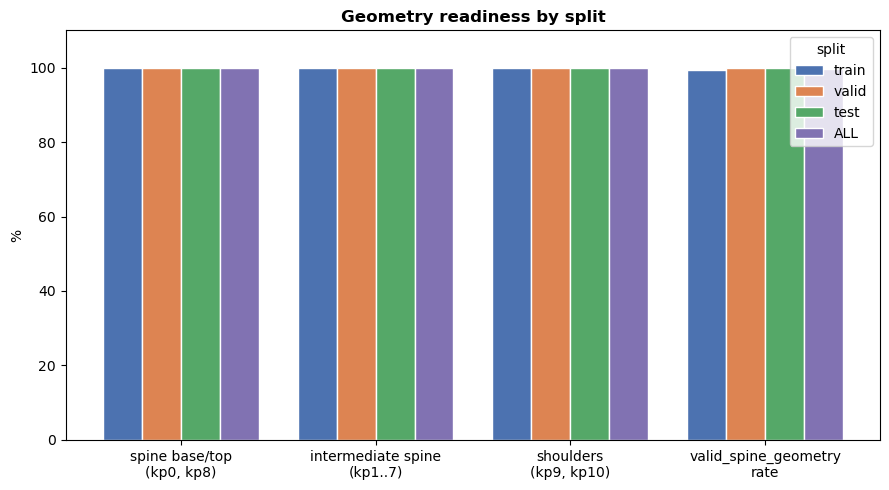

,split,base_top_visibility_pct,intermediate_visibility_pct,shoulder_visibility_pct,geometry_valid_pct
0,train,100.0,100.0,100.0,99.3
1,valid,100.0,100.0,100.0,100.0
2,test,100.0,100.0,100.0,100.0
3,ALL,100.0,100.0,100.0,99.5



Intermediate-keypoint (kp1..7) reliability verdict: reliable — treat lateral-deviation/curve-smoothness features as trustworthy


In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
metrics = ['base_top_visibility_pct', 'intermediate_visibility_pct', 'shoulder_visibility_pct', 'geometry_valid_pct']
metric_labels = ['spine base/top\n(kp0, kp8)', 'intermediate spine\n(kp1..7)', 'shoulders\n(kp9, kp10)', 'valid_spine_geometry\nrate']

x = np.arange(len(metrics))
width = 0.2
for i, split in enumerate(SPLITS + ['ALL']):
    row = geom_df[geom_df['split'] == split].iloc[0]
    vals = [row[m] for m in metrics]
    ax.bar(x + (i - 1.5) * width, vals, width, label=split, color=SPLIT_COLORS[split], edgecolor='white')

ax.set_xticks(x)
ax.set_xticklabels(metric_labels)
ax.set_ylim(0, 110)
ax.set_ylabel('%')
ax.set_title('Geometry readiness by split', fontweight='bold')
ax.legend(title='split')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_geometry_readiness.png', dpi=150, bbox_inches='tight')
plt.show()

display(geom_df)

all_row = geom_df[geom_df['split'] == 'ALL'].iloc[0]
verdict = geometry_reliability_verdict(all_row['intermediate_visibility_pct'])
print(f"\nIntermediate-keypoint (kp1..7) reliability verdict: {verdict}")

## Visual 6 — Sample overlays

**What this shows:** the actual ground-truth keypoints drawn on a real image, so the visibility
numbers above become something you can *see* rather than just percentages. Color legend:

- **Cyan line** — the kp[0] → kp[8] reference axis (spine base to spine top). Every anatomy-aware
  feature is measured relative to this line.
- **Orange dots** — intermediate spine points kp[1..7]. In a well-annotated image these should
  trace the visible curve of the back, not sit in a straight line on top of the cyan axis.
- **Magenta dots** — shoulders (kp[9], kp[10]).
- **Green dot** — head/neck center (kp[11]).

One example is shown per bucket:

- **`normal`** — a class-0 image with no flagged issues. Good case: cyan line runs cleanly from
  the small of the back to the neck, orange dots sit close to that line (little curvature).
- **`scoliosis`** — a class-1 image with no flagged issues. Good case: same cyan reference line,
  but the orange dots visibly bow away from it, tracing the actual spinal curve — this is exactly
  what `max_lateral_deviation_px` / `curve_smoothness_score` are designed to pick up on.
- **`problematic`** — an image that *was* flagged in Visual 3 (here, `kp_coord_out_of_range`). Bad
  case: notice the cyan line runs off the bottom edge of the frame instead of ending on the body —
  that's the out-of-range keypoint made visible. Other red flags to watch for if you inspect more
  images yourself: orange dots bunched at a single point (a collapsed/duplicate annotation), or
  points placed off the torso entirely.


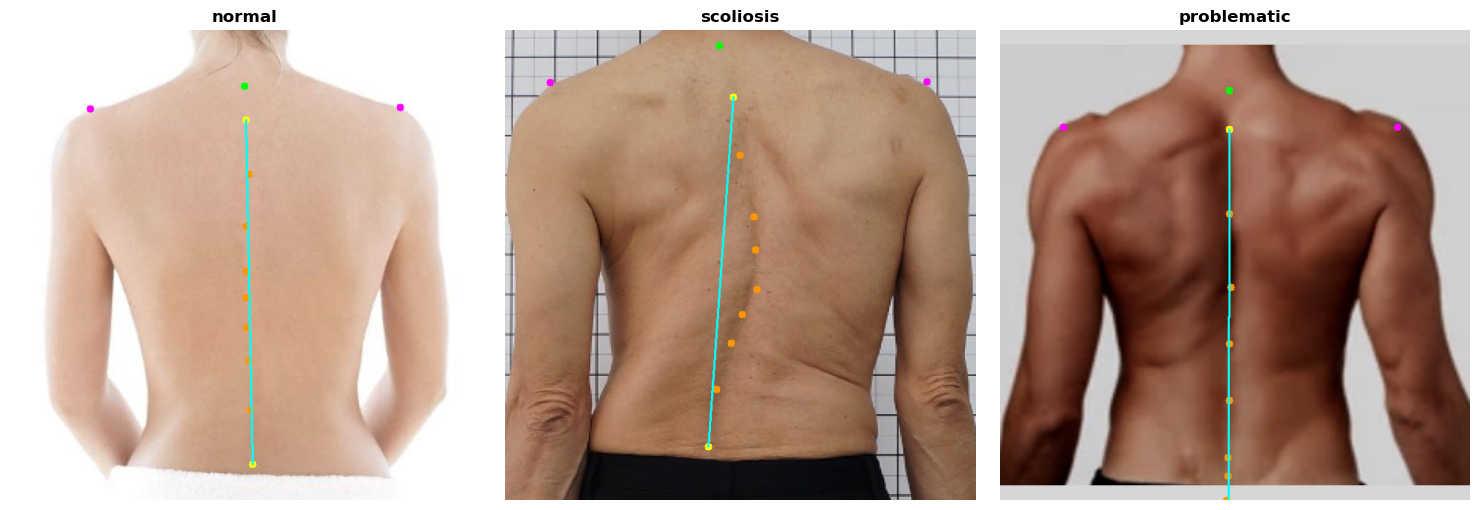

In [11]:
def first_sample(bucket):
    for res in split_results.values():
        if res['sample_pool'][bucket]:
            return res['sample_pool'][bucket][0]
    return None

def draw_overlay_rgb(img_path, objects):
    img = imdecode_unicode(img_path)
    h, w = img.shape[:2]
    colors = {
        'spine_base_top':     (0, 255, 255),
        'spine_intermediate': (0, 150, 255),
        'shoulders':          (255, 0, 255),
        'head_neck':          (0, 255, 0),
    }
    for obj in objects:
        base = top = None
        for i, (x, y, v) in enumerate(obj['keypoints']):
            if v < 2:
                continue
            px, py = int(x * w), int(y * h)
            group = next((g for g, idxs in KP_GROUPS.items() if i in idxs), 'other')
            cv2.circle(img, (px, py), 5, colors.get(group, (200, 200, 200)), -1)
            if i == 0:
                base = (px, py)
            if i == 8:
                top = (px, py)
        if base and top:
            cv2.line(img, base, top, (255, 255, 0), 2)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

if cv2 is None:
    print('cv2 not available — skipping inline sample overlays.')
else:
    buckets = ['normal', 'scoliosis', 'problematic']
    samples = {b: first_sample(b) for b in buckets}
    available = [b for b in buckets if samples[b] is not None]

    fig, axes = plt.subplots(1, len(available), figsize=(5 * len(available), 5))
    if len(available) == 1:
        axes = [axes]
    for ax, bucket in zip(axes, available):
        stem, img_path, objects = samples[bucket]
        ax.imshow(draw_overlay_rgb(img_path, objects))
        ax.set_title(bucket, fontweight='bold')
        ax.axis('off')
    plt.tight_layout()
    plt.show()

## Step 5 — Save sample overlays

Saves up to 3 overlay images per class/split/problem-bucket to
`Data/Processed/eda/sample_overlays/` 

The CSV summary tables and markdown report are **not** re-saved to disk from this notebook (they
duplicated `src/Evaluation/dataset_eda.py`'s own output) — run that script directly if you need
those files on disk.


In [12]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

save_sample_overlays(split_results, class_names)

print(f'Overlays written to: {(OUTPUT_DIR / "sample_overlays").relative_to(PROJECT_ROOT)}')

[INFO] Saved 21 sample overlay image(s) to Data\Processed\eda\sample_overlays
Overlays written to: Data\Processed\eda\sample_overlays


## Summary & conclusions

In [13]:
total_images = int(summary_df['num_images'].sum())
total_issues = len(issues_df)
all_row = geom_df[geom_df['split'] == 'ALL'].iloc[0]

print('=' * 60)
print('KEY CONCLUSIONS')
print('=' * 60)
print(f"Total images checked          : {total_images}")
print(f"Cross-split leakage detected  : {'YES' if dupe_hashes else 'no'}")
print(f"Files flagged with issues     : {total_issues}")
print(f"Geometry-valid label rate     : {all_row['geometry_valid_pct']}%")
print(f"kp1..7 reliability verdict    : {geometry_reliability_verdict(all_row['intermediate_visibility_pct'])}")
print()
print('Class imbalance ratio by split (majority:minority):')
for _, row in summary_df.iterrows():
    print(f"  {row['split']:6s}: {row['class_imbalance_ratio']}")

KEY CONCLUSIONS
Total images checked          : 191
Cross-split leakage detected  : no
Files flagged with issues     : 8
Geometry-valid label rate     : 99.5%
kp1..7 reliability verdict    : reliable — treat lateral-deviation/curve-smoothness features as trustworthy

Class imbalance ratio by split (majority:minority):
  train : 1.34
  valid : 1.12
  test  : 2.8


### Limitations to keep in mind

- This notebook measures **ground-truth label completeness**, not the trained model's runtime
  keypoint confidence — a fully-labeled dataset does not guarantee confident predictions at
  inference time.
- Class-imbalance and issue counts reflect *this* dataset snapshot; re-run this notebook after
  any dataset change (new images, re-annotation, a merged/combined dataset).
- `empty_label_file` flags are not automatically bugs — confirm with the dataset source whether
  they are intentional negative examples before removing them.

### Recommended next steps

1. Manually check the images/labels listed in `label_quality_issues.csv` (small in number here).
2. If the test-split imbalance ratio is high, treat scoliosis recall from `compare_workflows.py`
   as indicative only, and consider stratified re-splitting if more data becomes available.
3. Re-run `run_evaluation.py --model yolo_finetuned` and compare its *predicted* keypoint
   confidence against this notebook's *label* visibility rates — a large gap between the two
   would point to a model/inference problem rather than a data problem.